In [ ]:
import os
from typing import *
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import torch
from sklearn.manifold import TSNE
from tqdm import tqdm
import random
import pandas as pd

save_plots = False

if save_plots:
    dir_path = "plots/figure_3/"
    os.makedirs(dir_path, exist_ok=True)

mm = 1/25.4
width_sc = 180 // 3 * mm
height_sc = width_sc
figsize = (width_sc, height_sc)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Arial", "Helvetica"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.5,
    "lines.linewidth": 1.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False
})

np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

surrogate_model_path = "results/tdcl_full_online/nmnist/ff/neurons200/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up5_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs20/4/"
spike_model_path = "results/tdcl_full_online/nmnist/ff/neurons200_spike_grad/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up5_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs20/4/"

In [2]:
from src.util.dataloading import create_nmnist_dataloaders

train_loader, val_loader, test_loader = create_nmnist_dataloaders(
        batch_size=128,
        bins=100,
        filter_time=10000,
        num_workers=4,
        flatten=True,
        split_train=True,
        reset_cache=False,
    )

/home/thomas/Development/online-local-gesture-activation/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Input raster plot

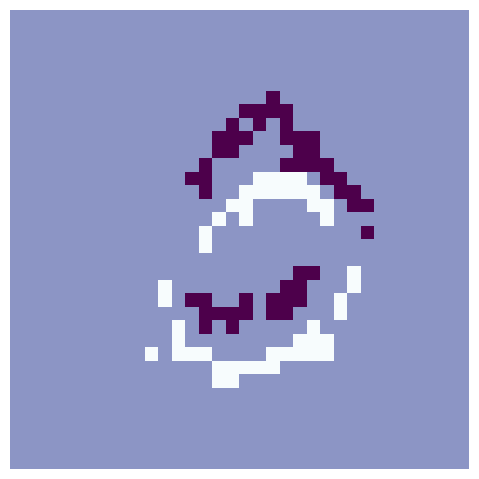

In [3]:
fig, ax = plt.subplots(1, 1)

x, y = next(iter(test_loader))

def create_digit_figure(x: torch.Tensor, index:int) -> tuple[plt.Figure, plt.Axes]:
    im = x[index, 0].reshape(2, 34, 34).cpu()
    im = im[0] - im[1]
    im = np.clip(im, a_min=-1, a_max=1)

    ax.imshow(im, cmap="BuPu")
    ax.axis("off")
    fig.tight_layout()
    return fig, ax

for index in [10, 20, 50]:
    fig, ax = create_digit_figure(x, index) 
    if save_plots:
        fig.savefig(dir_path + f"nmnist_sample_num_{index}.png", dpi=300, bbox_inches="tight")

# Kernel over activity

In [4]:
import torch
from torch import nn
import snntorch as snn
from snntorch import surrogate
import numpy as np
from matplotlib import pyplot as plt

import dill
from typing import Callable, Any

from typing import Union

class Block(nn.Module):
    def __init__(
            self, 
            in_features:int, 
            out_features:int, 
            beta:float, 
            spike_grad:Callable,
            init_hidden:bool,
        ) -> None:
        super().__init__()
        
        self.ff = nn.Linear(in_features, out_features, bias=False)
        nn.init.kaiming_uniform_(self.ff.weight, mode='fan_in', nonlinearity='tanh')
        self.leaky = snn.Leaky(beta=beta, spike_grad=spike_grad, init_hidden=init_hidden, output=True, learn_beta=False)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, Union[torch.Tensor, None]]:
        """
        input:
            x: presynaptic spikes: (T, B, C, H, W)
        output:
            spk_rec: (T, B, C', H', W')
            mem_rec: (T, B, C', H', W') | None
        """
        T = x.shape[0] 
        B = x.shape[1]
        x = x.reshape(T, B, -1) 
        spk_rec = []
        mem_rec = []
        # utils.reset(self)  # resets hidden states for all LIF neurons in net
        for t in range(T):  # x.size(0) = number of time steps
            spk_out, mem_out = self.leaky(self.ff(x[t]))
            spk_rec.append(spk_out)
            mem_rec.append(mem_out)
        
        spk_rec = torch.stack(spk_rec)
        mem_rec = torch.stack(mem_rec)
        return spk_rec, mem_rec
    
    def step(self, x:torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """
        input:
            x: presynaptic spikes: (B, N) or (B, C, H, W)
        output:
            spk_rec: (B, N')
            mem_rec: (B, N')
        """
        B = x.shape[0]
        x = x.reshape(B, -1)
        x = self.ff(x)
        spk_out, mem_out = self.leaky(x)
        return spk_out, mem_out
    
    def get_in_dim(self) -> torch.Tensor:
        return self.ff.in_features
    
    def get_out_dim(self) -> torch.Tensor:
        return self.ff.out_features

    def get_weight(self) -> torch.Tensor:
        return self.ff.weight
    
    def set_weight(self, weight:torch.Tensor) -> None:
        if isinstance(weight, torch.Tensor):
            weight = nn.Parameter(weight)
        self.ff.weight = weight

block1 = Block(
    in_features=2312, 
    out_features=200, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)
block2 = Block(
    in_features=200, 
    out_features=200, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)

def load_weights(path:str) -> None:
    checkpoint: dict[str, dict[str, Any]] = dill.load(open(path + "final_checkpoint.pkl", "rb"))
    block1.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_1"]["state_dict"].items() if "layer" in key})
    block2.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_2"]["state_dict"].items() if "layer" in key})

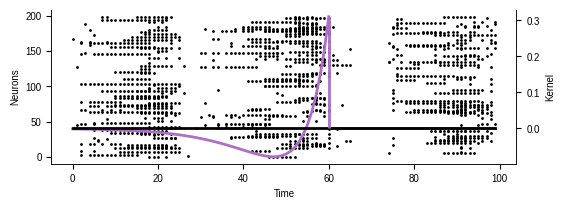

In [5]:
from snntorch import spikeplot

plt.rcParams.update({"axes.spines.right": True})

fig, ax = plt.subplots(1, 1, figsize=(6, 2))
ax2 = ax.twinx()

load_weights(surrogate_model_path)
x = x.to("cpu")
x1, _ = block1(x)

spikeplot.raster(x1[:,0,:], ax, s=1, c="black", clip_on=True)

def trace_over(x:np.ndarray, beta:float) -> np.ndarray:
    y = []
    buff = 0
    for value in x:
        buff = beta * buff + value
        y.append(buff)
    y = np.array(y)
    return y

spike = np.zeros(100,)
spike[39] = 1

gs = trace_over(spike, beta=0.9)
gf = trace_over(spike, beta=0.85)
g = 1.1816 * gf - 0.8714 * gs 
g = g[::-1]

lw = 2
c = "#ad6fc7"
ax2.plot(np.arange(61), g[:61], c=c, lw=lw)
ax2.plot(np.arange(60, 100), np.zeros_like(np.arange(60, 100)), c=c, lw=lw)
ax2.plot(np.zeros(100,), c="black", lw=lw)
ax2.vlines(x=60, ymin=0, ymax=g[60], colors=c, lw=lw)

ax.set_xlabel("Time")
ax.set_ylabel("Neurons")
ax2.set_ylabel("Kernel")

if save_plots:
    fig.savefig(dir_path + "kernel_over_activity.png", dpi=300, bbox_inches="tight")

# t-SNE plot 

In [6]:
def create_tsne_embed(data_loader: torch.utils.data.DataLoader, block1: Block, block2: Block, perplexity:int=30) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    xs1 = []
    xs2 = []
    ys = []
    device = "cuda" if torch.cuda.is_available() else "cpu"
    block1 = block1.to(device)
    block2 = block2.to(device)

    with torch.no_grad():
        for x, y in tqdm(data_loader):
            x = x.to(device)
            x, _ = block1(x)
            xs1.append(x.mean(dim=0).flatten(start_dim=1).detach().cpu().numpy())
            x, _ = block2(x)
            xs2.append(x.mean(dim=0).flatten(start_dim=1).detach().cpu().numpy())
            ys.append(y.detach().cpu().numpy())

    xs1 = np.concatenate(xs1, axis=0)
    xs2 = np.concatenate(xs2, axis=0)
    ys = np.concatenate(ys, axis=0)

    print("TSNE1")
    tsne = TSNE(n_components=2, perplexity=perplexity)
    tsne_embed1 = tsne.fit_transform(xs1)

    print("TSNE2")
    tsne = TSNE(n_components=2, perplexity=perplexity)
    tsne_embed2 = tsne.fit_transform(xs2)
    
    return tsne_embed1, tsne_embed2, ys


def plot_tsne(tsne_embed:np.ndarray, ys:np.ndarray) -> tuple[plt.Figure, plt.Axes]:
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    plt.rc('legend',  handlelength=0.5)
    plt.rc('legend',fontsize=7)
    plt.rc('font',  family='sans',)
    ax.axis("off")
    sns.scatterplot(
        x=tsne_embed[...,0], 
        y=tsne_embed[...,1], 
        hue=ys,
        palette=sns.color_palette("colorblind", 10),
        ax=ax,
        legend=True,
        s=7,
    )
    sns.move_legend(ax, "lower left", bbox_to_anchor=(1, 0))
    return fig, ax


def save_tsne_to_csv(tsne_embed:np.ndarray, ys:np.ndarray, name:str) -> None:
    data = {
        "x": tsne_embed[...,0],
        "y": tsne_embed[...,1],
        "label": ys
    }
    df = pd.DataFrame(data)
    df.to_csv(dir_path + name)


def reinit_weight(block: Block) -> None:
    w = torch.zeros_like(block.ff.weight)
    mean = block.ff.weight.mean().item()
    std = block.ff.weight.std().item()
    torch.nn.init.normal_(w, mean=mean, std=std, generator=None)
    block.ff.weight = nn.Parameter(w)

  0%|          | 0/79 [00:00<?, ?it/s]

100%|██████████| 79/79 [00:07<00:00, 11.00it/s]


TSNE1
TSNE2


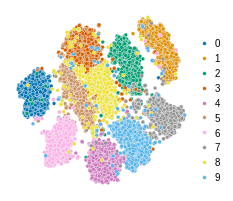

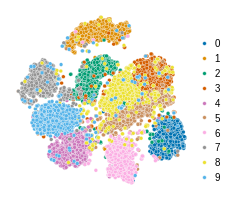

In [7]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

tsne_embed1, tsne_embed2, ys = create_tsne_embed(test_loader, block1, block2)

fig, ax = plot_tsne(tsne_embed1, ys)
if save_plots:
    name = "tsne_trained_layer1"
    save_tsne_to_csv(tsne_embed1, ys, name=name + ".csv")
    fig.savefig(dir_path + name + ".png", dpi=300, bbox_inches="tight")

fig, ax = plot_tsne(tsne_embed2, ys)
if save_plots:
    name = "tsne_trained_layer2"
    save_tsne_to_csv(tsne_embed2, ys, name=name + ".csv")
    fig.savefig(dir_path + name + ".png", dpi=300, bbox_inches="tight")

In [8]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

print(block1.ff.weight)
print(block2.ff.weight)

reinit_weight(block1)
reinit_weight(block2)

print(block1.ff.weight)
print(block2.ff.weight)

Parameter containing:
tensor([[-0.0070,  0.0566, -0.0035,  ..., -0.0312, -0.0204,  0.0090],
        [-0.0064, -0.0566, -0.0387,  ...,  0.0022, -0.0029, -0.0333],
        [ 0.0488,  0.0047, -0.0256,  ...,  0.0020, -0.0435,  0.0428],
        ...,
        [ 0.0329, -0.0412, -0.0467,  ..., -0.0316,  0.0228,  0.0514],
        [-0.0597, -0.0270,  0.0579,  ...,  0.0097,  0.0210, -0.0251],
        [ 0.0095,  0.0160,  0.0023,  ..., -0.0576, -0.0427,  0.0521]],
       device='cuda:0', requires_grad=True)
Parameter containing:
tensor([[-0.1488, -0.0165,  0.1919,  ..., -0.0581,  0.0479,  0.0016],
        [-0.1426, -0.0673, -0.1830,  ..., -0.1657,  0.3113, -0.0962],
        [-0.1269, -0.2730, -0.1113,  ...,  0.4428,  0.0645, -0.1128],
        ...,
        [ 0.0274, -0.2846,  0.1967,  ..., -0.4648,  0.1653,  0.0159],
        [-0.1650,  0.2890, -0.0950,  ...,  0.0090,  0.0740, -0.1159],
        [-0.1054, -0.4107, -0.3065,  ..., -0.1988, -0.0071,  0.0695]],
       device='cuda:0', requires_grad=True)


100%|██████████| 79/79 [00:06<00:00, 11.33it/s]


TSNE1
TSNE2


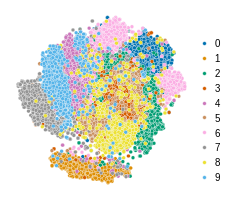

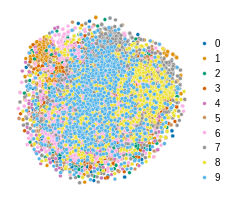

In [9]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

tsne_embed1, tsne_embed2, ys = create_tsne_embed(test_loader, block1, block2)

fig, ax = plot_tsne(tsne_embed1, ys)
if save_plots:
    name = "tsne_untrained_layer1"
    save_tsne_to_csv(tsne_embed1, ys, name=name + ".csv")
    fig.savefig(dir_path + name + ".png", dpi=300, bbox_inches="tight")

fig, ax = plot_tsne(tsne_embed2, ys)
if save_plots:
    name = "tsne_untrained_layer2"
    save_tsne_to_csv(tsne_embed2, ys, name=name + ".csv")
    fig.savefig(dir_path + name + ".png", dpi=300, bbox_inches="tight")

  0%|          | 0/79 [00:00<?, ?it/s]

100%|██████████| 79/79 [00:06<00:00, 11.45it/s]


TSNE1
TSNE2


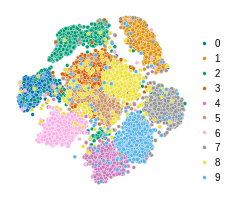

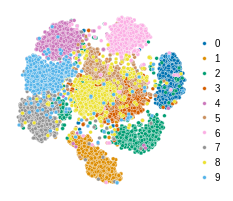

In [10]:
spike_model_path = spike_model_path[:-2]
spike_model_path += "4/"
load_weights(spike_model_path)

np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

tsne_embed1, tsne_embed2, ys = create_tsne_embed(test_loader, block1, block2)

fig, ax = plot_tsne(tsne_embed1, ys)
if save_plots:
    name = "tsne_trained_spike_only_layer1"
    save_tsne_to_csv(tsne_embed1, ys, name=name + ".csv")
    fig.savefig(dir_path + name + ".png", dpi=300, bbox_inches="tight")

fig, ax = plot_tsne(tsne_embed2, ys)
if save_plots:
    name = "tsne_trained_spike_only_layer2"
    save_tsne_to_csv(tsne_embed2, ys, name=name + ".csv")
    fig.savefig(dir_path + name + ".png", dpi=300, bbox_inches="tight")

# Cosine similarity

In [11]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

x, y = next(iter(train_loader))

x1 = x[:, None, :, :] # (T, 1, B, N) 
x2 = x[None, :, :, :] # (1, T, B, N)
sim = x1 * x2 # (T, T, B, N)
sim = sim.sum(axis=-1) # (T, T, B)

norm1 = torch.norm(x1, p=2, dim=-1)
norm1[norm1==0] = 1

norm2 = torch.norm(x2, p=2, dim=-1)
norm2[norm2==0] = 1

sim = sim / norm1
sim = sim / norm2
sim = sim.mean(axis=-1) # (T, T)

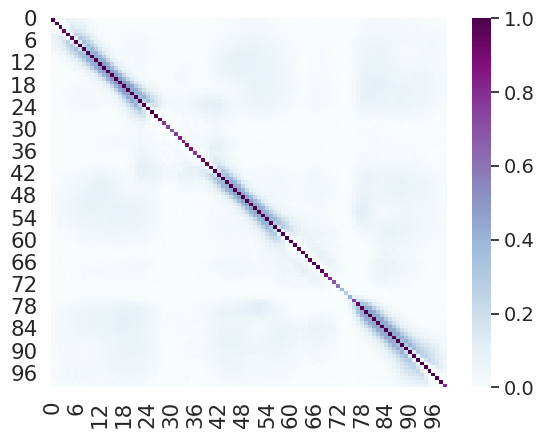

In [21]:
fig, ax = plt.subplots(1, 1)

df_cm = pd.DataFrame(sim, range(sim.shape[0]), range(sim.shape[1]))
sns.set(font_scale=1.4) # for label size
sns.heatmap(df_cm, annot=False, cmap="BuPu", ax=ax) # font size

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)

# ax.set_xticks([0, 50, 100])
# ax.set_yticks([])
# ax.set_xlabel("Time", fontdict={"size": 7})
# ax.set_ylabel("Time", fontdict={"size": 7})
# cbar.ax.set_ylabel("Cosine Similarity", fontdict={"size": 7})

if save_plots:
    name = "between_timestep_cosine_similarity"
    fig.savefig(dir_path + name + ".svg", bbox_inches="tight")
    data = {f"Timestep_{i}": sim[i,...] for i in range(sim.shape[0])}
    df = pd.DataFrame(data, data.keys())
    df.index.name = 'Timestep'
    df.to_csv(dir_path + name + ".csv")


plt.show()